<a href="https://colab.research.google.com/github/thesloth8600114677-ux/sea/blob/main/sumML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , OneHotEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score ,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    ExtraTreesClassifier

)


In [7]:
df = pd.read_csv('pokemon.csv')
df.head()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   #           800 non-null    int64 
 1   Name        800 non-null    object
 2   Type 1      800 non-null    object
 3   Type 2      414 non-null    object
 4   Total       800 non-null    int64 
 5   HP          800 non-null    int64 
 6   Attack      800 non-null    int64 
 7   Defense     800 non-null    int64 
 8   Sp. Atk     800 non-null    int64 
 9   Sp. Def     800 non-null    int64 
 10  Speed       800 non-null    int64 
 11  Generation  800 non-null    int64 
 12  Legendary   800 non-null    bool  
dtypes: bool(1), int64(9), object(3)
memory usage: 75.9+ KB


In [9]:
df.describe()

,#,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,362.813750,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,208.343798,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,1.000000,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,184.750000,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,364.500000,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,539.250000,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,721.000000,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


/tmp/ipykernel_964/1276696921.py:7: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


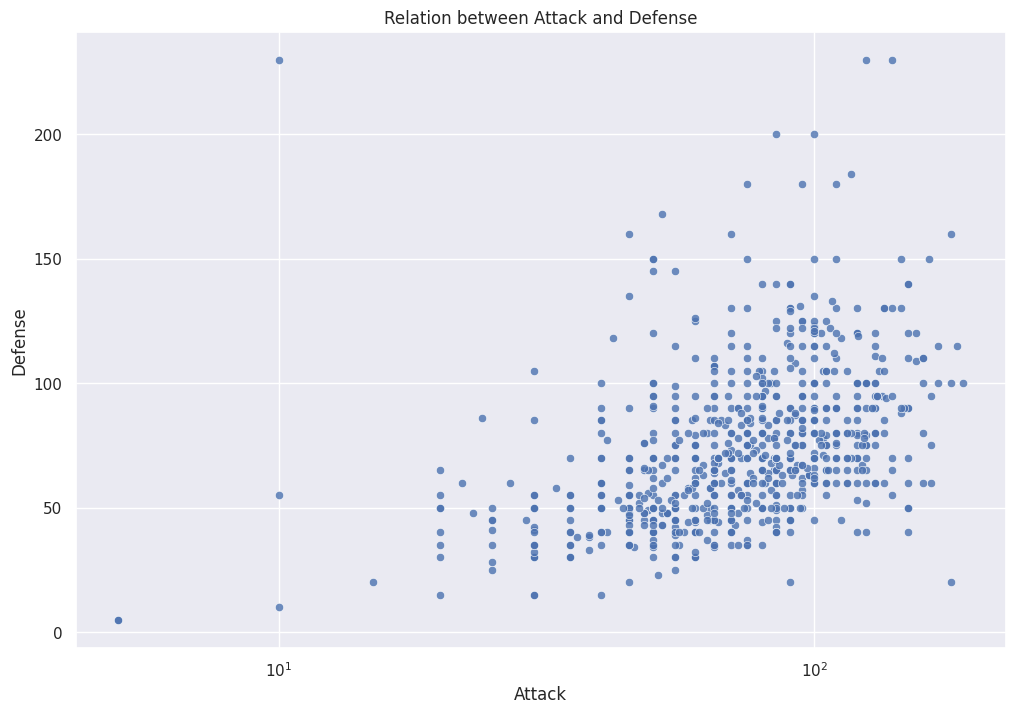

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

plt.figure(figsize=(12 ,8))
sns.scatterplot(
    data=df,
    x="Attack",
    y="Defense",
    palette="Set3",
    alpha=0.8,  # 'opacity' in Seaborn/Matplotlib is called 'alpha'
)

plt.xscale("log")  # Set x-axis to log scale
plt.title("Relation between Attack and Defense")
plt.show()

In [11]:
import plotly.express as px

fig1 = px.scatter(
    df,
    title="Relation between Attack and Defense",
    x="Attack",
    y="Defense",
    hover_data=["Sp. Atk", "Sp. Def", "Speed"],
    color_discrete_sequence=px.colors.qualitative.Set2,  # Fixed palette syntax
    opacity=0.8,
    template="seaborn",  # Sets a seaborn-like grid theme
)

fig1.update_traces(marker_size=5)
fig1.update_xaxes(type="log")
fig1.update_layout(width=800, height=500)

fig1.show()  # Display Plotly figure (removed plt.show())


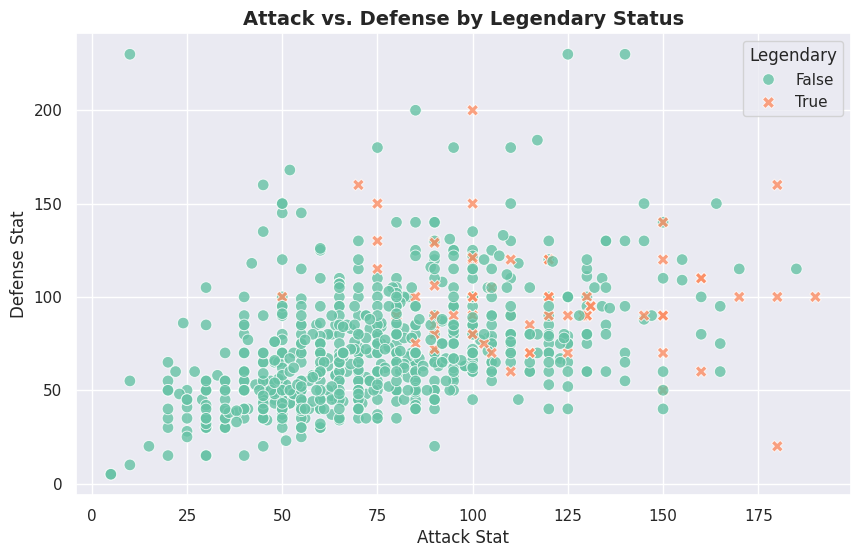

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Attack",
    y="Defense",
    hue="Legendary",
    style="Legendary",
    palette="Set2",
    s=70,  # Marker size
    alpha=0.8,
)

plt.title("Attack vs. Defense by Legendary Status", fontsize=14, fontweight="bold")
plt.xlabel("Attack Stat")
plt.ylabel("Defense Stat")
plt.show()

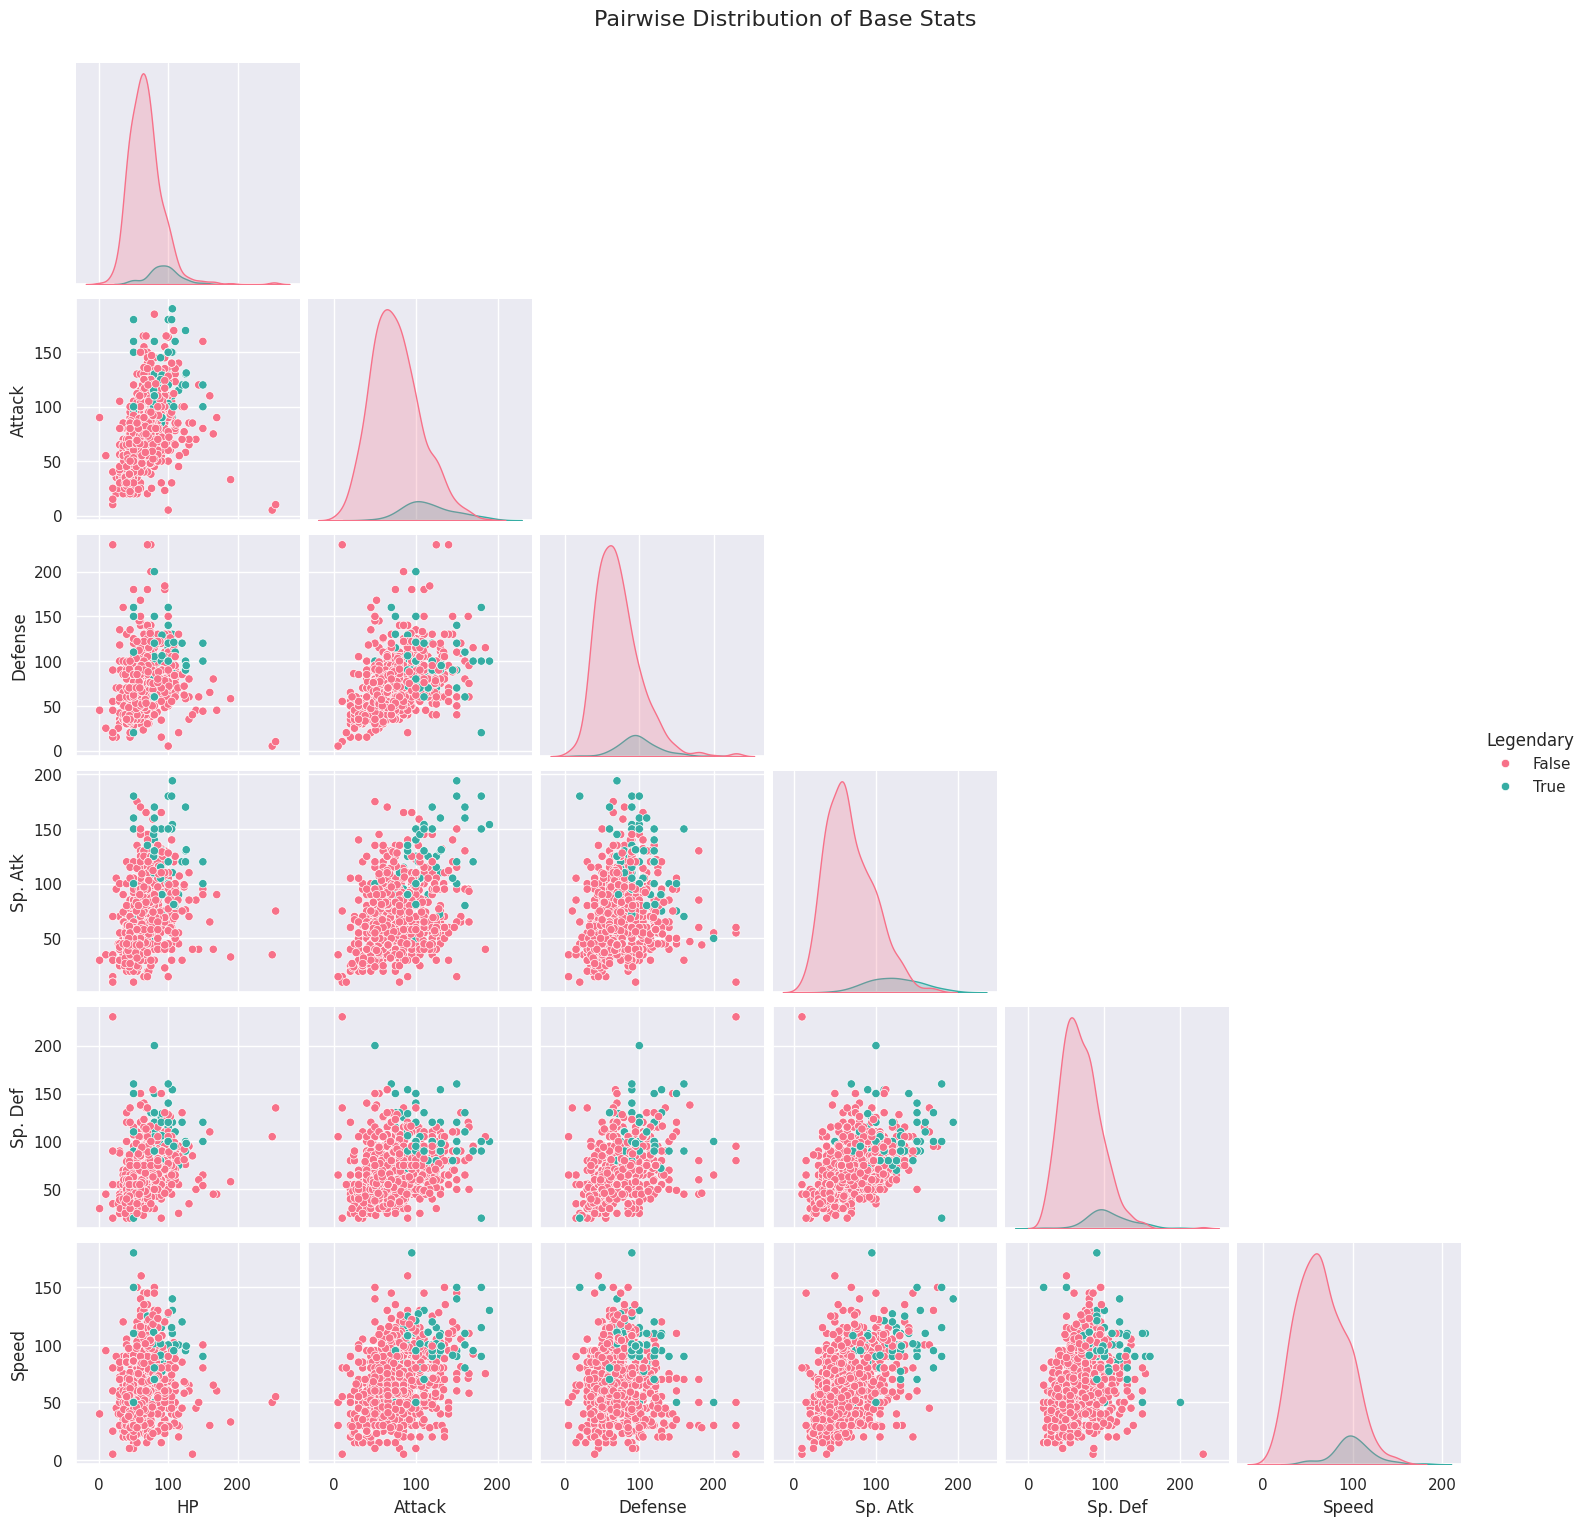

In [13]:
# Focus on key numerical stat columns
stat_cols = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]

sns.pairplot(
    df,
    vars=stat_cols,
    hue="Legendary",
    palette="husl",
    corner=True,  # Hides upper triangle to reduce clutter
)
plt.suptitle("Pairwise Distribution of Base Stats", y=1.02, fontsize=16)
plt.show()

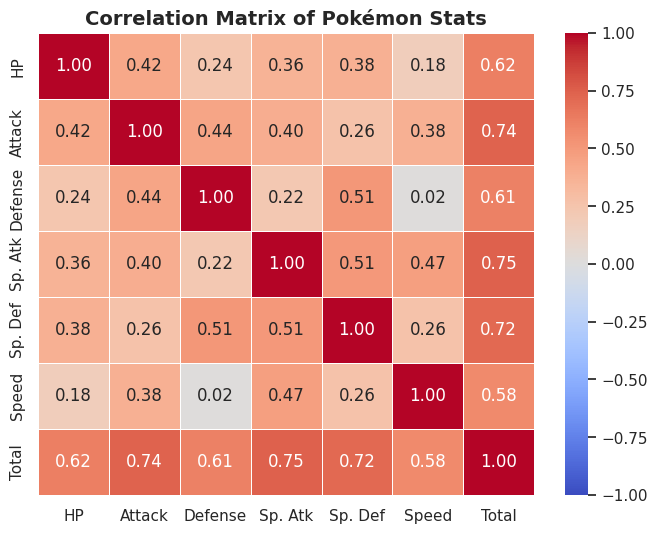

In [14]:
plt.figure(figsize=(8, 6))

numeric_df = df[["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed", "Total"]]
corr = numeric_df.corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)

plt.title("Correlation Matrix of Pokémon Stats", fontsize=14, fontweight="bold")
plt.show()

In [16]:
X = df.drop(columns=['Name', 'Legendary'],axis = 1)
y = df['Legendary']

In [17]:
categorical_cols = [
    'Type 1','Type 2'

]

numerical_cols =[
    'Total',	'HP',	'Attack',	'Defense'	,'Sp. Atk',	'Sp. Def','Speed','Generation'
]

In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown = 'ignore', sparse_output =False),categorical_cols)
    ]

)

In [20]:
X_train , X_test , y_train , y_test = train_test_split(
  X , y, test_size = 0.2 , random_state =42
)

In [24]:
models ={
    'Logistic Regression': LogisticRegression(
        max_iter = 2000 ,
        random_state = 42
    ),
    'Gaussian Naive bayes': GaussianNB(),
    'SVM(RBF)': SVC(
        kernel = 'rbf',
        C = 10,
        gamma = 0.1,
        probability = True
    ),
    "AdaBoost":AdaBoostClassifier(# adaboost is and esneble learning algorith
        n_estimators= 200,# it combines many weak learns (usually small decision trees  called decision stumps)
        random_state = 42# more trees usually imporove accuracy but increase traiining time
    ),
    'Gradient Boosting':GradientBoostingClassifier(# it its imprves adaboost by using gradient descent ideas to reduce prediction errors
        n_estimators = 200,# more trees can improve but also increase training time
        learning_rate = 0.1,# every atribute only contribute 10 percent
        random_state = 42
    ),

    "Extra Trees": ExtraTreesClassifier(# choose both random features  and random split thresold
        n_estimators = 300,# the final prediction is based on the vote of all 300 trees
        random_state = 42
    ),
    "XGBoost":XGBClassifier(# extreme Graient Boosting
        n_estimators = 300,# non of tree Each trees tries to coo=rrect the error of the prevoius ones
        learning_rate = 0.1,# control how much tree contribute
        random_state = 42,
        eval_metric = 'mlogloss'# multiclass Logarithmic lass
    )


}

In [25]:
voting =VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter = 2000 , random_state = 42)),
        ("svm", SVC(kernel="rbf", C=10, gamma = 0.01, probability =True)),
        ("xgb", XGBClassifier(
            eval_metric ="mlogloss",
            random_state = 42
        )),
        ("et", ExtraTreesClassifier(random_state =42))
    ],
    voting ="soft"
)


In [26]:
voting_pipeline =Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', voting)
])

voting_pipeline.fit(X_train , y_train)
pred = voting_pipeline.predict(X_test)

print("=" * 60)
print("Voting Classifier")
print(f"Accuracy : {accuracy_score(y_test, pred):.4f}")

Voting Classifier
Accuracy : 0.9625


In [32]:
# the loops for the model

results = {}

for name, clf in models.items():
  pipeline = Pipeline([
      ('preprocessor', preprocessor),
      ('classifier', clf)
  ])
  pipeline.fit(X_train ,y_train)
  train_pred = pipeline.predict(X_train)
  test_pred = pipeline.predict(X_test)

  if name == 'SVM(RBF)':
    svm_pipeline = pipeline
    svm_pred = test_pred

  train_acc = accuracy_score(y_train, train_pred)
  test_acc = accuracy_score(y_test , test_pred)

  results[name] = test_acc
  print('=' * 60)
  print(name)
  print(f"Train Accuracy : {train_acc:.4f}")
  print(f"Test Accuracy : {test_acc:.4f}")
  print(classification_report(y_test , test_pred))

Logistic Regression
Train Accuracy : 0.9594
Test Accuracy : 0.9688
              precision    recall  f1-score   support

       False       0.99      0.97      0.98       150
        True       0.69      0.90      0.78        10

    accuracy                           0.97       160
   macro avg       0.84      0.94      0.88       160
weighted avg       0.97      0.97      0.97       160

Gaussian Naive bayes
Train Accuracy : 0.3625
Test Accuracy : 0.3000
              precision    recall  f1-score   support

       False       0.93      0.27      0.42       150
        True       0.06      0.70      0.11        10

    accuracy                           0.30       160
   macro avg       0.50      0.49      0.27       160
weighted avg       0.88      0.30      0.40       160

SVM(RBF)
Train Accuracy : 1.0000
Test Accuracy : 0.9563
              precision    recall  f1-score   support

       False       0.99      0.96      0.98       150
        True       0.60      0.90      0.72   

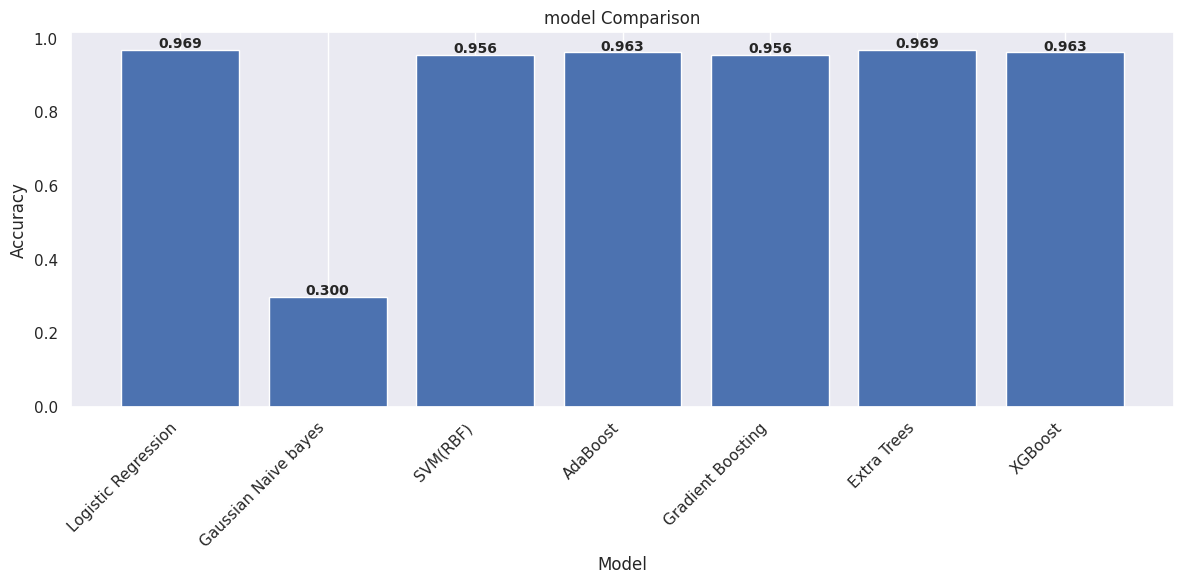

In [34]:
plt.figure(figsize = (12  , 6))

plt.bar(results.keys(), results.values())

plt.xticks(rotation = 45 , ha = 'right')#Horinzontal elingnment  =Right
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('model Comparison')
plt.grid(axis = 'y')


for i, score in enumerate(results.values()):
    plt.text(
        i,                  # X-position (bar index: 0, 1, 2...)
        score + 0.005,      # Y-position (slightly above the bar top)
        f"{score:.3f}",     # Formats score as a 3-decimal float (e.g., 0.945)
        ha="center",        # Center text over the bar
        fontsize=10,
        fontweight="bold"
    )


plt.tight_layout()
plt.show()